In [ ]:
fix = '''
import numpy as np

def read_header(fp):
    line = fp.readline().strip()
    if not line.startswith(b'#binvox'):
        raise IOError('Not a binvox file')
    dims = list(map(int, fp.readline().strip().split(b' ')[1:]))
    translate = list(map(float, fp.readline().strip().split(b' ')[1:]))
    scale = float(fp.readline().strip().split(b' ')[1])
    fp.readline()
    return dims, translate, scale

def read(fp):
    dims, translate, scale = read_header(fp)
    raw = fp.read()
    sz = dims[0] * dims[1] * dims[2]
    data = np.zeros(sz, dtype=bool)
    idx = 0
    i = 0
    while i < len(raw):
        val = raw[i]
        cnt = raw[i+1]
        i += 2
        if val:
            data[idx:idx+cnt] = True
        idx += cnt
    data = data.reshape(dims)
    class VoxelModel:
        pass
    m = VoxelModel()
    m.data = data
    m.dims = dims
    m.translate = translate
    m.scale = scale
    return m
'''
with open('/content/binvox_rw.py', 'w') as f:
    f.write(fix)
print("binvox_rw created!")

binvox_rw created!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile, os, shutil

CATEGORIES = {
    '03001627': 'chair',
    '04256520': 'sofa',
    '04379243': 'table',
    '03636649': 'lamp',
    '02958343': 'car',
    '02828884': 'bench',
}

print("Extracting renders...")
for folder_id, name in CATEGORIES.items():
    zip_path = f'/content/drive/MyDrive/ShapeNet/{folder_id}.zip'
    dst = f'/content/renders/{name}/{folder_id}'
    if os.path.exists(zip_path) and not os.path.exists(dst):
        os.makedirs(f'/content/renders/{name}', exist_ok=True)
        with zipfile.ZipFile(zip_path, 'r') as z:
            z.extractall(f'/content/renders/{name}')
        print(f"  {name} renders done!")
    else:
        print(f"  {name} renders skipped!")

print("Extracting voxels...")
for folder_id, name in CATEGORIES.items():
    zip_path = f'/content/drive/MyDrive/voxels/{folder_id}.zip'
    dst = f'/content/voxels/{name}/{folder_id}'
    if os.path.exists(zip_path) and not os.path.exists(dst):
        os.makedirs(f'/content/voxels/{name}', exist_ok=True)
        with zipfile.ZipFile(zip_path, 'r') as z:
            z.extractall(f'/content/voxels/{name}')
        print(f"  {name} voxels done!")
    else:
        print(f"  {name} voxels skipped!")

print("Fixing chairs renders...")
chairs_dst = '/content/renders/chair/03001627'
if not os.path.exists(chairs_dst):
    with zipfile.ZipFile('/content/drive/MyDrive/chairs_zip.zip', 'r') as z:
        z.extractall('/content/chairs_orig')
    src = '/content/chairs_orig/chairs/images'
    os.makedirs(chairs_dst, exist_ok=True)
    for model_id in os.listdir(src):
        s = os.path.join(src, model_id)
        d = os.path.join(chairs_dst, model_id)
        if not os.path.exists(d):
            shutil.copytree(s, d)
    print("Chairs fixed!")
else:
    print("Chairs already exist!")

print("All done!")

Mounted at /content/drive
Extracting renders...
  chair renders skipped!
  sofa renders done!
  table renders done!
  lamp renders done!
  car renders done!
  bench renders done!
Extracting voxels...
  chair voxels done!
  sofa voxels done!
  table voxels done!
  lamp voxels done!
  car voxels done!
  bench voxels done!
Fixing chairs renders...
Chairs fixed!
All done!


In [ ]:
import os, cv2, numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import binvox_rw

IMAGE_SIZE = 64
VOXEL_SIZE = 32
BATCH_SIZE = 16
EPOCHS     = 20
LR         = 1e-3

CATEGORIES = {
    '03001627': ('chair', 0),
    '04256520': ('sofa',  1),
    '04379243': ('table', 2),
    '03636649': ('lamp',  3),
    '02958343': ('car',   4),
    '02828884': ('bench', 5),
}

def render_to_sketch(image_path, size=64):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    img = cv2.resize(img, (256, 256))
    img = cv2.GaussianBlur(img, (3, 3), 0)
    edges = cv2.Canny(img, 30, 100)
    edges = cv2.resize(edges, (size, size))
    return edges.astype(np.float32) / 255.0

class MultiObjectDataset(Dataset):
    def __init__(self, voxel_size=32, image_size=64):
        self.voxel_size = voxel_size
        self.image_size = image_size
        self.pairs = []
        for folder_id, (name, label) in CATEGORIES.items():
            render_root = f'/content/renders/{name}/{folder_id}'
            voxel_root  = f'/content/voxels/{name}/{folder_id}'
            if not os.path.exists(render_root) or not os.path.exists(voxel_root):
                print(f"  Skipping {name} - missing data")
                continue
            count = 0
            for model_id in os.listdir(voxel_root):
                vox_path = os.path.join(voxel_root, model_id, 'model.binvox')
                if not os.path.exists(vox_path):
                    continue
                render_dir = os.path.join(render_root, model_id, 'rendering')
                render_path = None
                for idx in ['00', '01', '02', '03']:
                    candidate = os.path.join(render_dir, f'{idx}.png')
                    if os.path.exists(candidate):
                        render_path = candidate
                        break
                if render_path:
                    self.pairs.append((vox_path, render_path, label))
                    count += 1
            print(f"  {name:10s}: {count} pairs")
        print(f"\nTotal: {len(self.pairs)} pairs")

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        vox_path, render_path, label = self.pairs[idx]
        with open(vox_path, 'rb') as f:
            vox_model = binvox_rw.read(f)
        voxel = vox_model.data.astype(np.float32)
        if voxel.shape[0] != self.voxel_size:
            import torch.nn.functional as F
            vt = torch.tensor(voxel).unsqueeze(0).unsqueeze(0)
            vt = F.interpolate(vt, size=(self.voxel_size,)*3,
                               mode='trilinear', align_corners=False)
            voxel = vt.squeeze().numpy()
        sketch = render_to_sketch(render_path, self.image_size)
        if sketch is None:
            sketch = np.zeros((self.image_size, self.image_size), dtype=np.float32)
        return (torch.tensor(sketch).unsqueeze(0),
                torch.tensor(voxel).unsqueeze(0),
                label)

dataset    = MultiObjectDataset(VOXEL_SIZE, IMAGE_SIZE)
train_size = int(0.8 * len(dataset))
val_size   = len(dataset) - train_size
train_set, val_set = torch.utils.data.random_split(dataset, [train_size, val_size])
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Train: {train_size} | Val: {val_size}")

  chair     : 6778 pairs
  sofa      : 3173 pairs
  table     : 8509 pairs
  lamp      : 2318 pairs
  car       : 7496 pairs
  bench     : 1816 pairs

Total: 30090 pairs
Train: 24072 | Val: 6018


In [ ]:
import torch
import torch.nn as nn

class SketchEncoder(nn.Module):
    def __init__(self, latent_dim=512):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1),   nn.BatchNorm2d(32),  nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1),  nn.BatchNorm2d(64),  nn.ReLU(),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.Conv2d(128, 256, 4, 2, 1),nn.BatchNorm2d(256), nn.ReLU(),
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, latent_dim),
            nn.ReLU()
        )
    def forward(self, x):
        return self.net(x)

class VoxelDecoder(nn.Module):
    def __init__(self, latent_dim=512):
        super().__init__()
        self.fc = nn.Linear(latent_dim, 256 * 2 * 2 * 2)
        self.net = nn.Sequential(
            nn.ConvTranspose3d(256, 128, 4, 2, 1), nn.BatchNorm3d(128), nn.ReLU(),
            nn.ConvTranspose3d(128, 64, 4, 2, 1),  nn.BatchNorm3d(64),  nn.ReLU(),
            nn.ConvTranspose3d(64, 32, 4, 2, 1),   nn.BatchNorm3d(32),  nn.ReLU(),
            nn.ConvTranspose3d(32, 1, 4, 2, 1),
            nn.Sigmoid()
        )
    def forward(self, z):
        return self.net(self.fc(z).view(-1, 256, 2, 2, 2))

class Sketch3DNet(nn.Module):
    def __init__(self, latent_dim=512):
        super().__init__()
        self.encoder = SketchEncoder(latent_dim)
        self.decoder = VoxelDecoder(latent_dim)
    def forward(self, x):
        return self.decoder(self.encoder(x))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model  = Sketch3DNet(latent_dim=512).to(device)
print(f"Device: {device}")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Device: cpu
Parameters: 6,593,601


In [ ]:
import os

# Load final trained model
model_path = '/content/drive/MyDrive/multi_obj_final.pth'

# If final not saved, load latest checkpoint
if not os.path.exists(model_path):
    checkpoints = sorted([f for f in os.listdir('/content/drive/MyDrive')
                          if f.startswith('multi_obj_epoch')])
    if checkpoints:
        model_path = f'/content/drive/MyDrive/{checkpoints[-1]}'

model.load_state_dict(torch.load(model_path))
model.eval()
print(f"Model loaded from: {model_path}")
print("Ready to use!")

Model loaded from: /content/drive/MyDrive/multi_obj_epoch5.pth
Ready to use!


Upload one or more images (select all at once with Ctrl/Cmd+click)...


Saving Screenshot 2026-04-04 114117.png to Screenshot 2026-04-04 114117.png
Loaded 1 image(s): ['Screenshot 2026-04-04 114117.png']


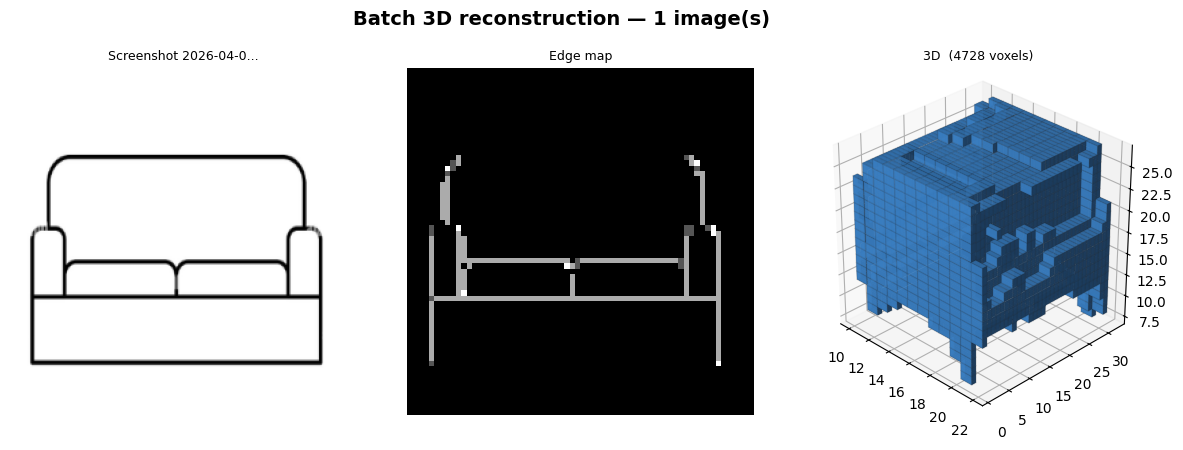

Saved → batch_3d_output.png


In [ ]:
from google.colab import files
import cv2, numpy as np, torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.ndimage import binary_closing, label
import math

# ── Upload multiple images ─────────────────────────────────────────────────
print("Upload one or more images (select all at once with Ctrl/Cmd+click)...")
uploaded = files.upload()
filenames = list(uploaded.keys())
print(f"Loaded {len(filenames)} image(s): {filenames}")

# ── Per-image pipeline ─────────────────────────────────────────────────────
def process_image(filename):
    img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)
    img_display = cv2.resize(img.copy(), (256, 256))
    img_r = cv2.resize(img, (256, 256))
    img_blur = cv2.GaussianBlur(img_r, (3, 3), 0)
    edges = cv2.Canny(img_blur, 30, 100)
    edges_64 = cv2.resize(edges, (64, 64)).astype(np.float32) / 255.0

    sketch_t = torch.tensor(edges_64).unsqueeze(0).unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(sketch_t).cpu().squeeze().numpy()

    # Fixed threshold + no dilation
    pred_binary = (pred > np.percentile(pred, 85))
    labeled, num = label(pred_binary)
    if num > 1:
        sizes = [(labeled == i).sum() for i in range(1, num+1)]
        pred_binary = (labeled == (np.argmax(sizes) + 1))
    pred_binary = binary_closing(pred_binary, structure=np.ones((2,2,2)))
    labeled, num = label(pred_binary)
    if num > 1:
        sizes = [(labeled == i).sum() for i in range(1, num+1)]
        pred_binary = (labeled == (np.argmax(sizes) + 1))

    return img_display, edges_64, pred_binary

# ── Layout: 3 columns per image (original | edges | 3D) ───────────────────
n = len(filenames)
cols_per_img = 3
fig_w = 5 * cols_per_img
fig_h = 4.5 * n

fig = plt.figure(figsize=(fig_w, fig_h), facecolor='white')
gs = gridspec.GridSpec(n, cols_per_img, figure=fig,
                         hspace=0.35, wspace=0.08)

for row, fname in enumerate(filenames):
    img_d, edges_d, pred_b = process_image(fname)
    label_name = fname[:20] + ('...' if len(fname) > 20 else '')
    voxel_count = pred_b.sum()

    ax1 = fig.add_subplot(gs[row, 0])
    ax1.imshow(img_d, cmap='gray')
    ax1.set_title(f'{label_name}', fontsize=9)
    ax1.axis('off')

    ax2 = fig.add_subplot(gs[row, 1])
    ax2.imshow(edges_d, cmap='gray')
    ax2.set_title('Edge map', fontsize=9)
    ax2.axis('off')

    ax3 = fig.add_subplot(gs[row, 2], projection='3d')
    colors = np.zeros(pred_b.shape + (4,))
    colors[pred_b] = [0.25, 0.55, 0.85, 0.90]
    ax3.voxels(pred_b, facecolors=colors, edgecolor=(0.15,0.15,0.15,0.1))
    ax3.set_title(f'3D  ({voxel_count} voxels)', fontsize=9)
    ax3.set_box_aspect([1,1,1])
    ax3.view_init(elev=30, azim=-45)

fig.suptitle(f'Batch 3D reconstruction — {n} image(s)',
             fontsize=14, fontweight='bold', y=1.01)
plt.savefig('batch_3d_output.png', dpi=130,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved → batch_3d_output.png")

Upload one or more images (select all at once with Ctrl/Cmd+click)...


Saving Screenshot 2026-04-04 114142.png to Screenshot 2026-04-04 114142.png
Loaded 1 image(s): ['Screenshot 2026-04-04 114142.png']


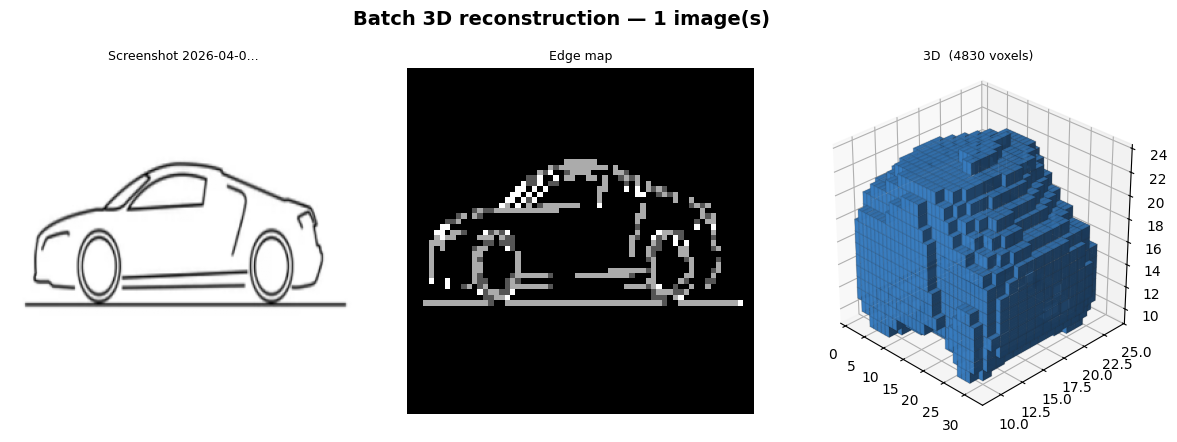

Saved → batch_3d_output.png


In [ ]:
from google.colab import files
import cv2, numpy as np, torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.ndimage import binary_closing, label
import math

# ── Upload multiple images ─────────────────────────────────────────────────
print("Upload one or more images (select all at once with Ctrl/Cmd+click)...")
uploaded = files.upload()
filenames = list(uploaded.keys())
print(f"Loaded {len(filenames)} image(s): {filenames}")

# ── Per-image pipeline ─────────────────────────────────────────────────────
def process_image(filename):
    img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)
    img_display = cv2.resize(img.copy(), (256, 256))
    img_r = cv2.resize(img, (256, 256))
    img_blur = cv2.GaussianBlur(img_r, (3, 3), 0)
    edges = cv2.Canny(img_blur, 30, 100)
    edges_64 = cv2.resize(edges, (64, 64)).astype(np.float32) / 255.0

    sketch_t = torch.tensor(edges_64).unsqueeze(0).unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(sketch_t).cpu().squeeze().numpy()

    # Fixed threshold + no dilation
    pred_binary = (pred > np.percentile(pred, 85))
    labeled, num = label(pred_binary)
    if num > 1:
        sizes = [(labeled == i).sum() for i in range(1, num+1)]
        pred_binary = (labeled == (np.argmax(sizes) + 1))
    pred_binary = binary_closing(pred_binary, structure=np.ones((2,2,2)))
    labeled, num = label(pred_binary)
    if num > 1:
        sizes = [(labeled == i).sum() for i in range(1, num+1)]
        pred_binary = (labeled == (np.argmax(sizes) + 1))

    return img_display, edges_64, pred_binary

# ── Layout: 3 columns per image (original | edges | 3D) ───────────────────
n = len(filenames)
cols_per_img = 3
fig_w = 5 * cols_per_img
fig_h = 4.5 * n

fig = plt.figure(figsize=(fig_w, fig_h), facecolor='white')
gs = gridspec.GridSpec(n, cols_per_img, figure=fig,
                         hspace=0.35, wspace=0.08)

for row, fname in enumerate(filenames):
    img_d, edges_d, pred_b = process_image(fname)
    label_name = fname[:20] + ('...' if len(fname) > 20 else '')
    voxel_count = pred_b.sum()

    ax1 = fig.add_subplot(gs[row, 0])
    ax1.imshow(img_d, cmap='gray')
    ax1.set_title(f'{label_name}', fontsize=9)
    ax1.axis('off')

    ax2 = fig.add_subplot(gs[row, 1])
    ax2.imshow(edges_d, cmap='gray')
    ax2.set_title('Edge map', fontsize=9)
    ax2.axis('off')

    ax3 = fig.add_subplot(gs[row, 2], projection='3d')
    colors = np.zeros(pred_b.shape + (4,))
    colors[pred_b] = [0.25, 0.55, 0.85, 0.90]
    ax3.voxels(pred_b, facecolors=colors, edgecolor=(0.15,0.15,0.15,0.1))
    ax3.set_title(f'3D  ({voxel_count} voxels)', fontsize=9)
    ax3.set_box_aspect([1,1,1])
    ax3.view_init(elev=30, azim=-45)

fig.suptitle(f'Batch 3D reconstruction — {n} image(s)',
             fontsize=14, fontweight='bold', y=1.01)
plt.savefig('batch_3d_output.png', dpi=130,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved → batch_3d_output.png")

Upload one or more images (select all at once with Ctrl/Cmd+click)...


Saving Screenshot 2026-04-04 114005.png to Screenshot 2026-04-04 114005.png
Loaded 1 image(s): ['Screenshot 2026-04-04 114005.png']


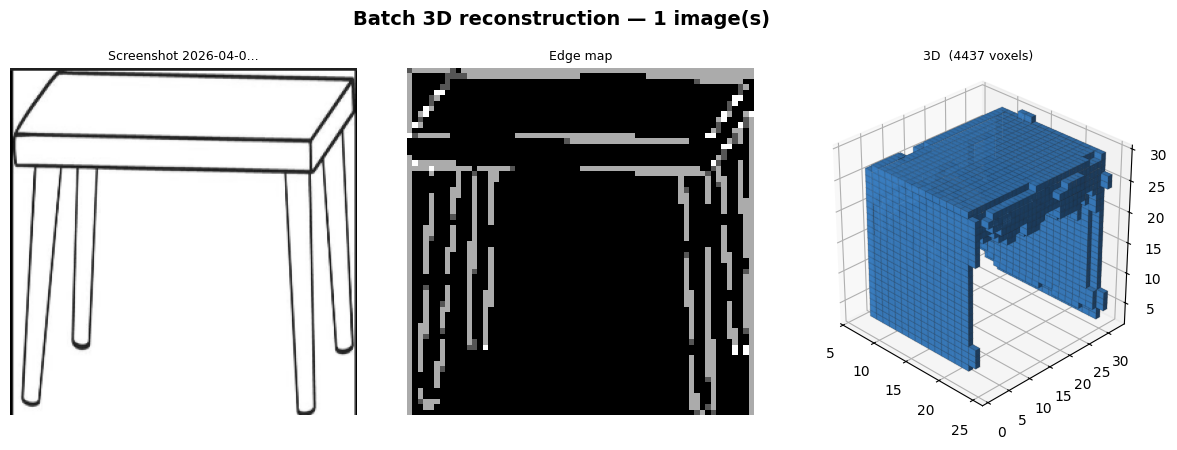

Saved → batch_3d_output.png


In [ ]:
from google.colab import files
import cv2, numpy as np, torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.ndimage import binary_closing, label
import math

# ── Upload multiple images ─────────────────────────────────────────────────
print("Upload one or more images (select all at once with Ctrl/Cmd+click)...")
uploaded = files.upload()
filenames = list(uploaded.keys())
print(f"Loaded {len(filenames)} image(s): {filenames}")

# ── Per-image pipeline ─────────────────────────────────────────────────────
def process_image(filename):
    img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)
    img_display = cv2.resize(img.copy(), (256, 256))
    img_r = cv2.resize(img, (256, 256))
    img_blur = cv2.GaussianBlur(img_r, (3, 3), 0)
    edges = cv2.Canny(img_blur, 30, 100)
    edges_64 = cv2.resize(edges, (64, 64)).astype(np.float32) / 255.0

    sketch_t = torch.tensor(edges_64).unsqueeze(0).unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(sketch_t).cpu().squeeze().numpy()

    # Fixed threshold + no dilation
    pred_binary = (pred > np.percentile(pred, 85))
    labeled, num = label(pred_binary)
    if num > 1:
        sizes = [(labeled == i).sum() for i in range(1, num+1)]
        pred_binary = (labeled == (np.argmax(sizes) + 1))
    pred_binary = binary_closing(pred_binary, structure=np.ones((2,2,2)))
    labeled, num = label(pred_binary)
    if num > 1:
        sizes = [(labeled == i).sum() for i in range(1, num+1)]
        pred_binary = (labeled == (np.argmax(sizes) + 1))

    return img_display, edges_64, pred_binary

# ── Layout: 3 columns per image (original | edges | 3D) ───────────────────
n = len(filenames)
cols_per_img = 3
fig_w = 5 * cols_per_img
fig_h = 4.5 * n

fig = plt.figure(figsize=(fig_w, fig_h), facecolor='white')
gs = gridspec.GridSpec(n, cols_per_img, figure=fig,
                         hspace=0.35, wspace=0.08)

for row, fname in enumerate(filenames):
    img_d, edges_d, pred_b = process_image(fname)
    label_name = fname[:20] + ('...' if len(fname) > 20 else '')
    voxel_count = pred_b.sum()

    ax1 = fig.add_subplot(gs[row, 0])
    ax1.imshow(img_d, cmap='gray')
    ax1.set_title(f'{label_name}', fontsize=9)
    ax1.axis('off')

    ax2 = fig.add_subplot(gs[row, 1])
    ax2.imshow(edges_d, cmap='gray')
    ax2.set_title('Edge map', fontsize=9)
    ax2.axis('off')

    ax3 = fig.add_subplot(gs[row, 2], projection='3d')
    colors = np.zeros(pred_b.shape + (4,))
    colors[pred_b] = [0.25, 0.55, 0.85, 0.90]
    ax3.voxels(pred_b, facecolors=colors, edgecolor=(0.15,0.15,0.15,0.1))
    ax3.set_title(f'3D  ({voxel_count} voxels)', fontsize=9)
    ax3.set_box_aspect([1,1,1])
    ax3.view_init(elev=30, azim=-45)

fig.suptitle(f'Batch 3D reconstruction — {n} image(s)',
             fontsize=14, fontweight='bold', y=1.01)
plt.savefig('batch_3d_output.png', dpi=130,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved → batch_3d_output.png")

Upload one or more images (select all at once with Ctrl/Cmd+click)...


Saving Screenshot 2026-04-04 104125.png to Screenshot 2026-04-04 104125.png
Loaded 1 image(s): ['Screenshot 2026-04-04 104125.png']


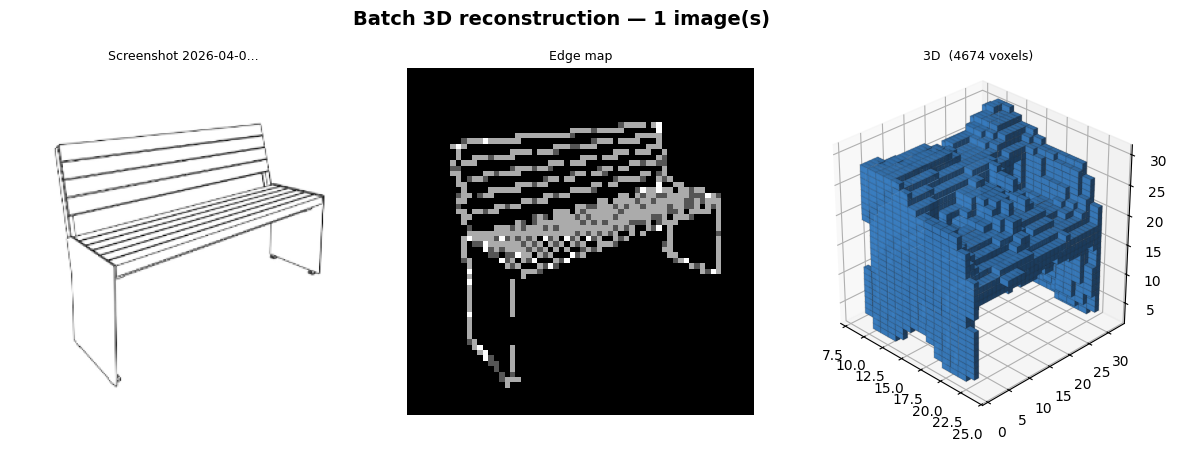

Saved → batch_3d_output.png


In [ ]:
from google.colab import files
import cv2, numpy as np, torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.ndimage import binary_closing, label
import math

# ── Upload multiple images ─────────────────────────────────────────────────
print("Upload one or more images (select all at once with Ctrl/Cmd+click)...")
uploaded = files.upload()
filenames = list(uploaded.keys())
print(f"Loaded {len(filenames)} image(s): {filenames}")

# ── Per-image pipeline ─────────────────────────────────────────────────────
def process_image(filename):
    img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)
    img_display = cv2.resize(img.copy(), (256, 256))
    img_r = cv2.resize(img, (256, 256))
    img_blur = cv2.GaussianBlur(img_r, (3, 3), 0)
    edges = cv2.Canny(img_blur, 30, 100)
    edges_64 = cv2.resize(edges, (64, 64)).astype(np.float32) / 255.0

    sketch_t = torch.tensor(edges_64).unsqueeze(0).unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(sketch_t).cpu().squeeze().numpy()

    # Fixed threshold + no dilation
    pred_binary = (pred > np.percentile(pred, 85))
    labeled, num = label(pred_binary)
    if num > 1:
        sizes = [(labeled == i).sum() for i in range(1, num+1)]
        pred_binary = (labeled == (np.argmax(sizes) + 1))
    pred_binary = binary_closing(pred_binary, structure=np.ones((2,2,2)))
    labeled, num = label(pred_binary)
    if num > 1:
        sizes = [(labeled == i).sum() for i in range(1, num+1)]
        pred_binary = (labeled == (np.argmax(sizes) + 1))

    return img_display, edges_64, pred_binary

# ── Layout: 3 columns per image (original | edges | 3D) ───────────────────
n = len(filenames)
cols_per_img = 3
fig_w = 5 * cols_per_img
fig_h = 4.5 * n

fig = plt.figure(figsize=(fig_w, fig_h), facecolor='white')
gs = gridspec.GridSpec(n, cols_per_img, figure=fig,
                         hspace=0.35, wspace=0.08)

for row, fname in enumerate(filenames):
    img_d, edges_d, pred_b = process_image(fname)
    label_name = fname[:20] + ('...' if len(fname) > 20 else '')
    voxel_count = pred_b.sum()

    ax1 = fig.add_subplot(gs[row, 0])
    ax1.imshow(img_d, cmap='gray')
    ax1.set_title(f'{label_name}', fontsize=9)
    ax1.axis('off')

    ax2 = fig.add_subplot(gs[row, 1])
    ax2.imshow(edges_d, cmap='gray')
    ax2.set_title('Edge map', fontsize=9)
    ax2.axis('off')

    ax3 = fig.add_subplot(gs[row, 2], projection='3d')
    colors = np.zeros(pred_b.shape + (4,))
    colors[pred_b] = [0.25, 0.55, 0.85, 0.90]
    ax3.voxels(pred_b, facecolors=colors, edgecolor=(0.15,0.15,0.15,0.1))
    ax3.set_title(f'3D  ({voxel_count} voxels)', fontsize=9)
    ax3.set_box_aspect([1,1,1])
    ax3.view_init(elev=30, azim=-45)

fig.suptitle(f'Batch 3D reconstruction — {n} image(s)',
             fontsize=14, fontweight='bold', y=1.01)
plt.savefig('batch_3d_output.png', dpi=130,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved → batch_3d_output.png")

In [ ]:
def compute_iou(pred, target, threshold=0.3):
    pred_binary   = (pred > threshold).float()
    target_binary = (target > 0.5).float()
    intersection  = (pred_binary * target_binary).sum()
    union         = ((pred_binary + target_binary) > 0).float().sum()
    iou           = intersection / (union + 1e-8)
    return iou.item()

# Test IoU on validation set
model.eval()
total_iou = 0
count     = 0

with torch.no_grad():
    for sketches, voxels, labels in val_loader:
        sketches = sketches.to(device)
        voxels   = voxels.to(device)
        preds    = model(sketches)
        for i in range(len(preds)):
            iou = compute_iou(preds[i], voxels[i])
            total_iou += iou
            count += 1

avg_iou = total_iou / count
print(f"Average IoU: {avg_iou:.4f}")
print(f"IoU Percentage: {avg_iou*100:.2f}%")

Average IoU: 0.6545
IoU Percentage: 65.45%


In [ ]:
import os

print("Content folder:")
print(os.listdir('/content'))

Content folder:
['.config', 'batch_3d_output.png', 'drive', 'Screenshot 2026-04-04 104125.png', 'Screenshot 2026-04-04 114142.png', 'renders', 'Screenshot 2026-04-04 114117.png', 'Screenshot 2026-04-04 114005.png', 'binvox_rw.py', 'voxels', 'chairs_orig', '__pycache__', 'sample_data']



=== PERFORMANCE METRICS ===
Category          IoU   Accuracy
-----------------------------------
Chair          0.5700     0.9495
Sofa           0.7345     0.9647
Table          0.6235     0.9593
Lamp           0.4351     0.9685
Car            0.8342     0.9822
Bench          0.5310     0.9740
-----------------------------------
Average        0.6545     0.9648


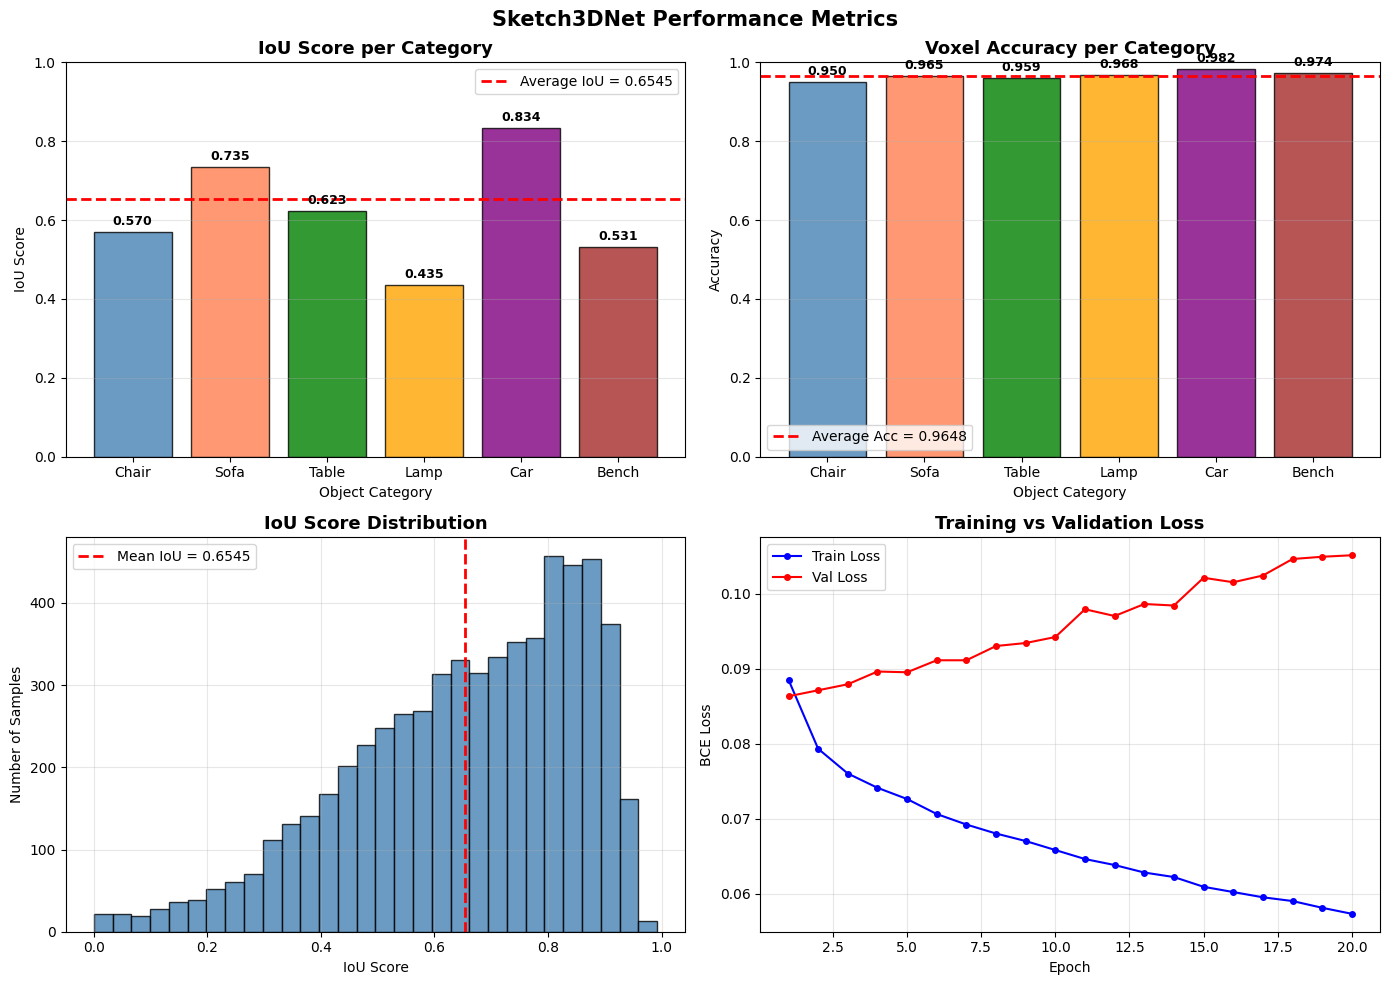

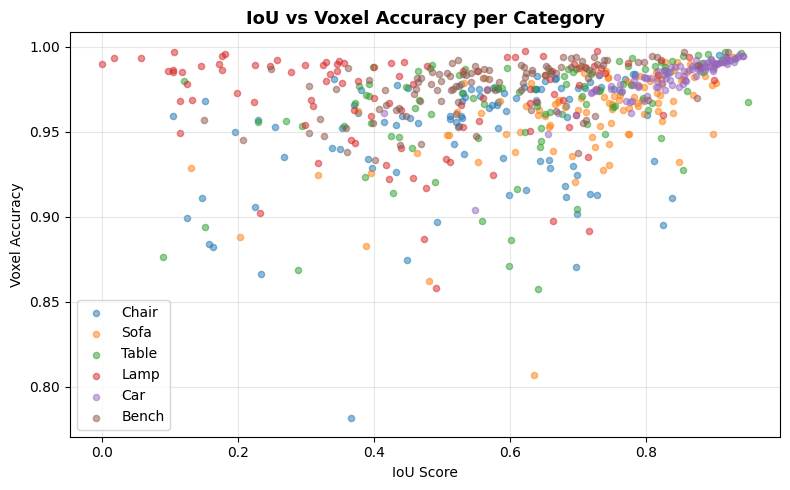


Final Summary:
Average IoU      : 0.6545 (65.45%)
Average Accuracy : 0.9648 (96.48%)


In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np

def compute_iou(pred, target, threshold=0.3):
    pred_binary   = (pred > threshold).float()
    target_binary = (target > 0.5).float()
    intersection  = (pred_binary * target_binary).sum()
    union         = ((pred_binary + target_binary) > 0).float().sum()
    return (intersection / (union + 1e-8)).item()

def compute_voxel_accuracy(pred, target, threshold=0.3):
    pred_binary   = (pred > threshold).float()
    target_binary = (target > 0.5).float()
    correct = (pred_binary == target_binary).float().sum()
    total   = pred_binary.numel()
    return (correct / total).item()

# ============================================
# Collect metrics per category
# ============================================
LABEL_NAMES = {0:'Chair', 1:'Sofa', 2:'Table', 3:'Lamp', 4:'Car', 5:'Bench'}

model.eval()
category_iou      = {i: [] for i in range(6)}
category_accuracy = {i: [] for i in range(6)}
all_iou           = []
all_accuracy      = []

with torch.no_grad():
    for sketches, voxels, labels in val_loader:
        sketches = sketches.to(device)
        voxels   = voxels.to(device)
        preds    = model(sketches)

        for i in range(len(preds)):
            iou      = compute_iou(preds[i], voxels[i])
            accuracy = compute_voxel_accuracy(preds[i], voxels[i])
            label    = labels[i].item()

            category_iou[label].append(iou)
            category_accuracy[label].append(accuracy)
            all_iou.append(iou)
            all_accuracy.append(accuracy)

# Compute averages
avg_iou_per_cat = [np.mean(category_iou[i]) for i in range(6)]
avg_acc_per_cat = [np.mean(category_accuracy[i]) for i in range(6)]
avg_iou_total   = np.mean(all_iou)
avg_acc_total   = np.mean(all_accuracy)

print(f"\n=== PERFORMANCE METRICS ===")
print(f"{'Category':<10} {'IoU':>10} {'Accuracy':>10}")
print("-" * 35)
for i in range(6):
    print(f"{LABEL_NAMES[i]:<10} {avg_iou_per_cat[i]:>10.4f} {avg_acc_per_cat[i]:>10.4f}")
print("-" * 35)
print(f"{'Average':<10} {avg_iou_total:>10.4f} {avg_acc_total:>10.4f}")

# ============================================
# Plot 1 — IoU per Category Bar Chart
# ============================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

categories = [LABEL_NAMES[i] for i in range(6)]
colors     = ['steelblue', 'coral', 'green', 'orange', 'purple', 'brown']

ax1 = axes[0, 0]
bars = ax1.bar(categories, avg_iou_per_cat, color=colors, edgecolor='black', alpha=0.8)
ax1.axhline(y=avg_iou_total, color='red', linestyle='--', linewidth=2, label=f'Average IoU = {avg_iou_total:.4f}')
ax1.set_title('IoU Score per Category', fontsize=13, fontweight='bold')
ax1.set_xlabel('Object Category')
ax1.set_ylabel('IoU Score')
ax1.set_ylim(0, 1)
ax1.legend()
ax1.grid(axis='y', alpha=0.3)
for bar, val in zip(bars, avg_iou_per_cat):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# ============================================
# Plot 2 — Voxel Accuracy per Category
# ============================================
ax2 = axes[0, 1]
bars2 = ax2.bar(categories, avg_acc_per_cat, color=colors, edgecolor='black', alpha=0.8)
ax2.axhline(y=avg_acc_total, color='red', linestyle='--', linewidth=2, label=f'Average Acc = {avg_acc_total:.4f}')
ax2.set_title('Voxel Accuracy per Category', fontsize=13, fontweight='bold')
ax2.set_xlabel('Object Category')
ax2.set_ylabel('Accuracy')
ax2.set_ylim(0, 1)
ax2.legend()
ax2.grid(axis='y', alpha=0.3)
for bar, val in zip(bars2, avg_acc_per_cat):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# ============================================
# Plot 3 — IoU Distribution Histogram
# ============================================
ax3 = axes[1, 0]
ax3.hist(all_iou, bins=30, color='steelblue', edgecolor='black', alpha=0.8)
ax3.axvline(x=avg_iou_total, color='red', linestyle='--', linewidth=2,
            label=f'Mean IoU = {avg_iou_total:.4f}')
ax3.set_title('IoU Score Distribution', fontsize=13, fontweight='bold')
ax3.set_xlabel('IoU Score')
ax3.set_ylabel('Number of Samples')
ax3.legend()
ax3.grid(alpha=0.3)

# ============================================
# Plot 4 — Training Loss Curve
# ============================================
ax4 = axes[1, 1]
train_losses = [0.0885, 0.0793, 0.0760, 0.0741, 0.0726, 0.0706, 0.0692,
                0.0680, 0.0670, 0.0658, 0.0646, 0.0638, 0.0628, 0.0622,
                0.0609, 0.0602, 0.0595, 0.0590, 0.0581, 0.0573]
val_losses   = [0.0863, 0.0871, 0.0879, 0.0896, 0.0895, 0.0911, 0.0911,
                0.0930, 0.0934, 0.0942, 0.0979, 0.0970, 0.0986, 0.0984,
                0.1021, 0.1015, 0.1024, 0.1046, 0.1049, 0.1051]

ax4.plot(range(1, 21), train_losses, 'b-o', markersize=4, label='Train Loss')
ax4.plot(range(1, 21), val_losses,   'r-o', markersize=4, label='Val Loss')
ax4.set_title('Training vs Validation Loss', fontsize=13, fontweight='bold')
ax4.set_xlabel('Epoch')
ax4.set_ylabel('BCE Loss')
ax4.legend()
ax4.grid(alpha=0.3)

plt.suptitle('Sketch3DNet Performance Metrics', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================
# Plot 5 — IoU vs Accuracy Scatter
# ============================================
plt.figure(figsize=(8, 5))
for i in range(6):
    plt.scatter(category_iou[i][:100],
                category_accuracy[i][:100],
                label=LABEL_NAMES[i], alpha=0.5, s=20)
plt.xlabel('IoU Score')
plt.ylabel('Voxel Accuracy')
plt.title('IoU vs Voxel Accuracy per Category', fontsize=13, fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nFinal Summary:")
print(f"Average IoU      : {avg_iou_total:.4f} ({avg_iou_total*100:.2f}%)")
print(f"Average Accuracy : {avg_acc_total:.4f} ({avg_acc_total*100:.2f}%)")

Voxel file path: /content/voxels/chair/03001627/4fd20c1142b642221403e6cccbe91852/model.binvox
Voxel shape: (32, 32, 32)
Voxel format: .binvox
Filled voxels: 680.0


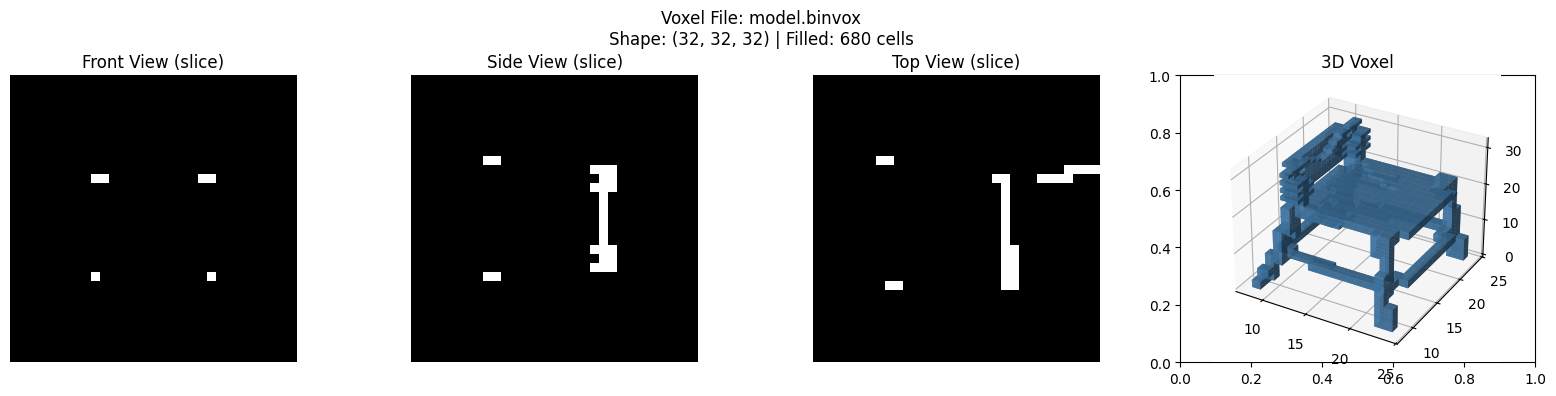

Saved to Drive!


<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import binvox_rw
import os

# Find a voxel file
vox_path = '/content/voxels/chair/03001627'
model_id = os.listdir(vox_path)[0]
vox_file = os.path.join(vox_path, model_id, 'model.binvox')

print(f"Voxel file path: {vox_file}")

# Load and visualize
with open(vox_file, 'rb') as f:
    vox_model = binvox_rw.read(f)

voxel = vox_model.data.astype(np.float32)
print(f"Voxel shape: {voxel.shape}")
print(f"Voxel format: .binvox")
print(f"Filled voxels: {voxel.sum()}")

# Show 3 views — front, side, top
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# Front view
axes[0].imshow(voxel[:, :, 16], cmap='gray')
axes[0].set_title('Front View (slice)')
axes[0].axis('off')

# Side view
axes[1].imshow(voxel[16, :, :], cmap='gray')
axes[1].set_title('Side View (slice)')
axes[1].axis('off')

# Top view
axes[2].imshow(voxel[:, 16, :], cmap='gray')
axes[2].set_title('Top View (slice)')
axes[2].axis('off')

# Full 3D
ax3d = fig.add_subplot(1, 4, 4, projection='3d')
ax3d.voxels(voxel > 0.5, facecolors='steelblue', alpha=0.8)
ax3d.set_title('3D Voxel')

plt.suptitle(f'Voxel File: model.binvox\nShape: {voxel.shape} | Filled: {int(voxel.sum())} cells', fontsize=12)
plt.tight_layout()
plt.show()

# Save to Drive
plt.savefig('/content/drive/MyDrive/voxel_sample.png', dpi=150, bbox_inches='tight')
print("Saved to Drive!")

In [ ]:
import os

# Check voxel files in Drive
print("Voxel zips in Drive:")
for f in os.listdir('/content/drive/MyDrive/voxels'):
    print(f"  {f}")

# Check extracted voxels in Colab
print("\nExtracted voxels in Colab:")
for name in ['chair', 'sofa', 'table', 'lamp', 'car', 'bench']:
    path = f'/content/voxels/{name}'
    if os.path.exists(path):
        count = sum([len(files) for r, d, files in os.walk(path)])
        print(f"  {name}: {count} files")
    else:
        print(f"  {name}: NOT extracted yet")

Voxel zips in Drive:
  02958343.zip
  03001627.zip
  03636649.zip
  04256520.zip
  04379243.zip
  02828884.zip

Extracted voxels in Colab:
  chair: 6778 files
  sofa: 3173 files
  table: 8509 files
  lamp: 2318 files
  car: 7496 files
  bench: 1816 files


VOXEL FILE INFORMATION
File Name    : model.binvox
File Path    : /content/voxels/chair/03001627/4fd20c1142b642221403e6cccbe91852/model.binvox
File Size    : 1374 bytes
File Format  : Binary Voxel (.binvox)
Model ID     : 4fd20c1142b642221403e6cccbe91852
Category     : Chair
Drive Path   : MyDrive/voxels/03001627.zip

VOXEL GRID DETAILS
Grid Shape   : (32, 32, 32) (32 x 32 x 32)
Total Cells  : 32768
Filled Cells : 680 (solid)
Empty Cells  : 32088 (air)
Fill Ratio   : 2.08%


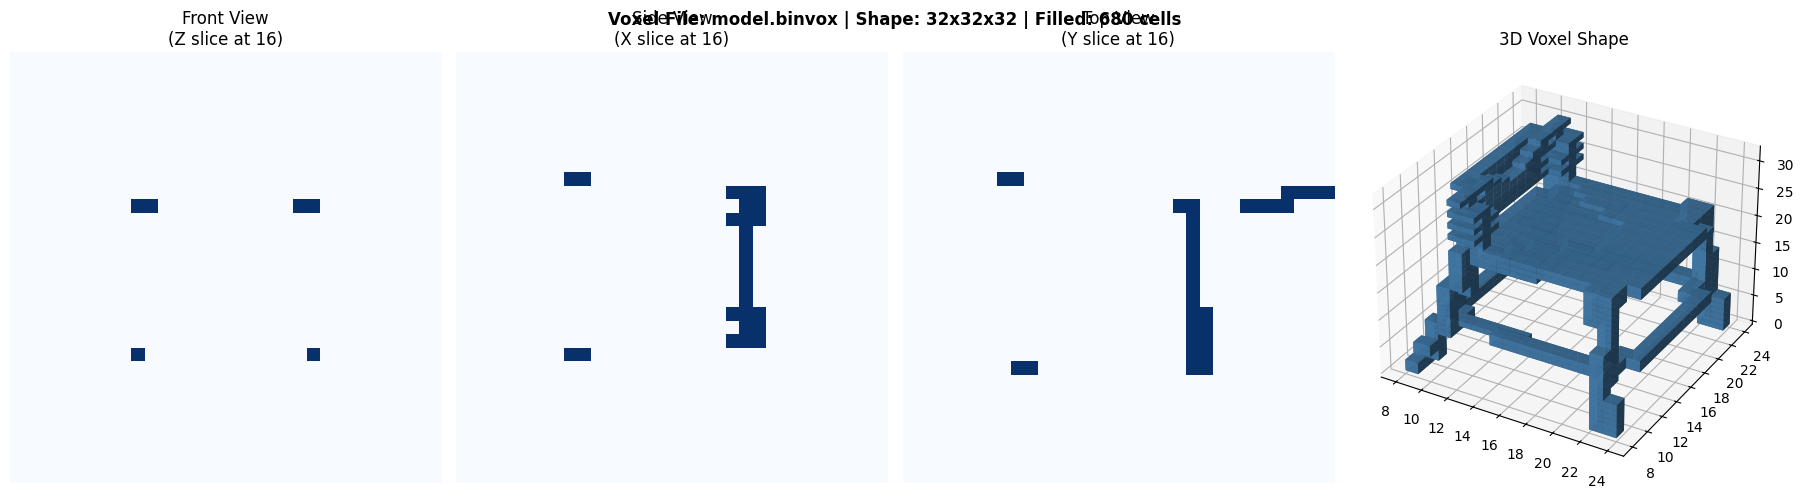


Saved to Drive as voxel_visualization.png!


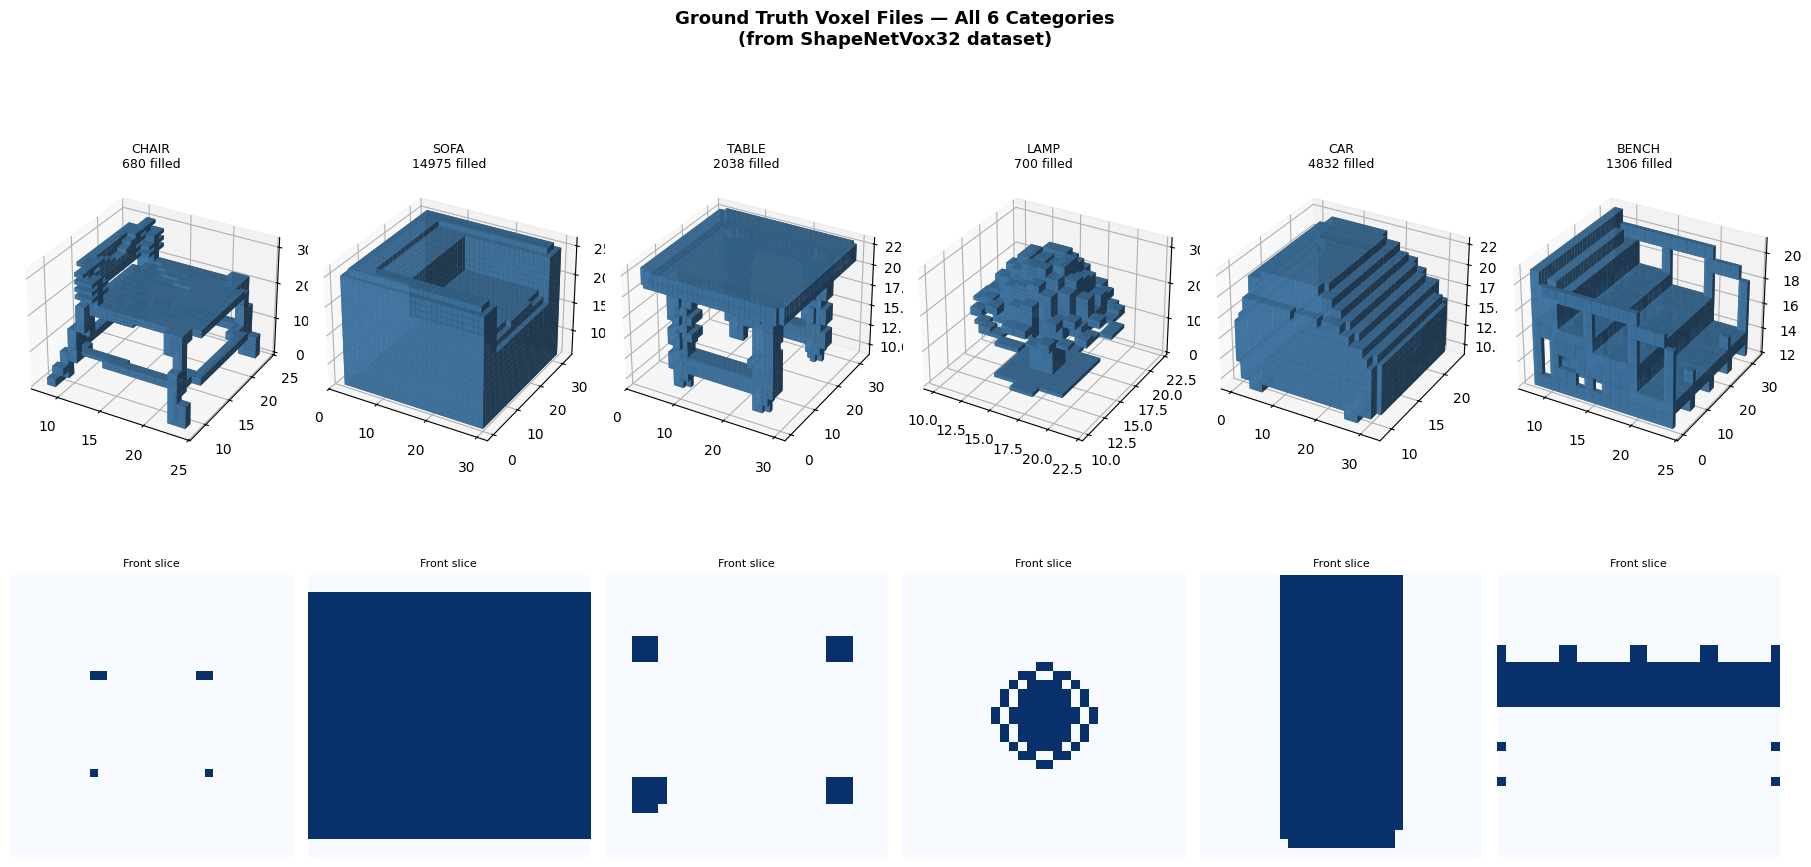

All categories voxel visualization saved to Drive!


In [ ]:
import os, binvox_rw, numpy as np
import matplotlib.pyplot as plt

# ============================================
# 1. Show file location and info
# ============================================
vox_root = '/content/voxels/chair/03001627'
model_id = os.listdir(vox_root)[0]
vox_file = os.path.join(vox_root, model_id, 'model.binvox')

print("=" * 50)
print("VOXEL FILE INFORMATION")
print("=" * 50)
print(f"File Name    : model.binvox")
print(f"File Path    : {vox_file}")
print(f"File Size    : {os.path.getsize(vox_file)} bytes")
print(f"File Format  : Binary Voxel (.binvox)")
print(f"Model ID     : {model_id}")
print(f"Category     : Chair")
print(f"Drive Path   : MyDrive/voxels/03001627.zip")

# ============================================
# 2. Load and show voxel details
# ============================================
with open(vox_file, 'rb') as f:
    vox_model = binvox_rw.read(f)

voxel = vox_model.data.astype(np.float32)
print("\n" + "=" * 50)
print("VOXEL GRID DETAILS")
print("=" * 50)
print(f"Grid Shape   : {voxel.shape} (32 x 32 x 32)")
print(f"Total Cells  : {voxel.size}")
print(f"Filled Cells : {int(voxel.sum())} (solid)")
print(f"Empty Cells  : {voxel.size - int(voxel.sum())} (air)")
print(f"Fill Ratio   : {voxel.mean()*100:.2f}%")

# ============================================
# 3. Visualize voxel file
# ============================================
fig = plt.figure(figsize=(18, 5))

# Front slice
ax1 = fig.add_subplot(141)
ax1.imshow(voxel[:, :, 16], cmap='Blues')
ax1.set_title('Front View\n(Z slice at 16)')
ax1.axis('off')

# Side slice
ax2 = fig.add_subplot(142)
ax2.imshow(voxel[16, :, :], cmap='Blues')
ax2.set_title('Side View\n(X slice at 16)')
ax2.axis('off')

# Top slice
ax3 = fig.add_subplot(143)
ax3.imshow(voxel[:, 16, :], cmap='Blues')
ax3.set_title('Top View\n(Y slice at 16)')
ax3.axis('off')

# Full 3D voxel
ax4 = fig.add_subplot(144, projection='3d')
ax4.voxels(voxel > 0.5, facecolors='steelblue', alpha=0.9)
ax4.set_title('3D Voxel Shape')

plt.suptitle(f'Voxel File: model.binvox | Shape: 32x32x32 | Filled: {int(voxel.sum())} cells',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/voxel_visualization.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nSaved to Drive as voxel_visualization.png!")

# ============================================
# 4. Show voxels for all 6 categories
# ============================================
CATEGORIES = {
    'chair': '03001627',
    'sofa':  '04256520',
    'table': '04379243',
    'lamp':  '03636649',
    'car':   '02958343',
    'bench': '02828884',
}

fig2 = plt.figure(figsize=(18, 10))
for i, (name, folder_id) in enumerate(CATEGORIES.items()):
    vox_root = f'/content/voxels/{name}/{folder_id}'
    model_id = os.listdir(vox_root)[0]
    vox_file = os.path.join(vox_root, model_id, 'model.binvox')

    with open(vox_file, 'rb') as f:
        vox_model = binvox_rw.read(f)
    voxel = vox_model.data.astype(np.float32)

    # 3D plot
    ax = fig2.add_subplot(2, 6, i+1, projection='3d')
    ax.voxels(voxel > 0.5, facecolors='steelblue', alpha=0.9)
    ax.set_title(f'{name.upper()}\n{int(voxel.sum())} filled', fontsize=9)

    # 2D slice
    ax2d = fig2.add_subplot(2, 6, i+7)
    ax2d.imshow(voxel[:, :, 16], cmap='Blues')
    ax2d.set_title(f'Front slice', fontsize=8)
    ax2d.axis('off')

plt.suptitle('Ground Truth Voxel Files — All 6 Categories\n(from ShapeNetVox32 dataset)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/all_voxels.png', dpi=150, bbox_inches='tight')
plt.show()
print("All categories voxel visualization saved to Drive!")

In [ ]:
import torch.optim as optim
from tqdm import tqdm

optimizer = optim.Adam(model.parameters(), lr=LR)
criterion = nn.BCELoss()
train_losses, val_losses = [], []

for epoch in range(last_epoch + 1, EPOCHS + 1):
    model.train()
    running_loss = 0
    for sketches, voxels, labels in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}"):
        sketches = sketches.to(device)
        voxels   = voxels.to(device)
        optimizer.zero_grad()
        preds = model(sketches)
        loss  = criterion(preds, voxels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)
    train_losses.append(train_loss)

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for sketches, voxels, labels in val_loader:
            sketches = sketches.to(device)
            voxels   = voxels.to(device)
            preds    = model(sketches)
            val_loss += criterion(preds, voxels).item()
    val_loss /= len(val_loader)
    val_losses.append(val_loss)

    print(f"Epoch {epoch:02d} | Train: {train_loss:.4f} | Val: {val_loss:.4f}")

    if epoch % 5 == 0:
        torch.save(model.state_dict(),
                   f'/content/drive/MyDrive/multi_obj_epoch{epoch}.pth')
        print(f"  Checkpoint saved!")